# The "Last Mile" Logistics Auditor — Veridi Logistics
**Question from the CEO:** *Are we failing specific regions, or is this a nationwide problem?*

This notebook audits delivery performance on the Olist e-commerce dataset and links **logistics outcomes** (did the parcel arrive when we promised?) to **customer sentiment** (how did the customer rate it?).

| Section | Maps to |
|---|---|
| 1. Schema Builder | User Story 1 |
| 2. "Real" Delay Calculator | User Story 2 |
| 3. Geographic Heatmap | User Story 3 |
| 4. Sentiment Correlation | User Story 4 |
| 5. Translation Challenge | Bonus |
| 6. Candidate's Choice: *Recalibrated ETA* | Section 6 of the brief |
| 7. Findings and exports | Executive summary |

**Reproducibility:** every file is read with a relative path, so place the CSVs next to this notebook. Required: `olist_orders_dataset.csv`, `olist_order_reviews_dataset.csv`, `olist_customers_dataset.csv`, `olist_products_dataset.csv`. Optional (enables the category bonus): `olist_order_items_dataset.csv`, `product_category_name_translation.csv`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import json, warnings
warnings.filterwarnings("ignore")

DATA = Path(".")            # relative path: CSVs live next to the notebook
FIG = Path("figures"); FIG.mkdir(exist_ok=True)

NAVY, RED, AMBER, GREEN, GREY = "#1F3A5F", "#C0392B", "#E69F00", "#2E8B57", "#9AA5B1"
STATUS_COLORS = {"On Time": GREEN, "Late": AMBER, "Super Late": RED}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 13, "font.size": 10})
pct = lambda x: f"{x*100:.1f}%"

## 1. The Schema Builder — Orders + Customers + Reviews in one table (Story 1)

In [2]:
orders = pd.read_csv(DATA/"olist_orders_dataset.csv",
                     parse_dates=["order_purchase_timestamp","order_approved_at","order_delivered_carrier_date",
                                  "order_delivered_customer_date","order_estimated_delivery_date"])
reviews   = pd.read_csv(DATA/"olist_order_reviews_dataset.csv", parse_dates=["review_creation_date","review_answer_timestamp"])
customers = pd.read_csv(DATA/"olist_customers_dataset.csv", dtype={"customer_zip_code_prefix": str})
products  = pd.read_csv(DATA/"olist_products_dataset.csv")

for name, df in {"orders": orders, "reviews": reviews, "customers": customers, "products": products}.items():
    print(f"{name:10s} {df.shape[0]:>7,} rows x {df.shape[1]} cols")

orders      99,441 rows x 8 cols
reviews     99,224 rows x 7 cols
customers   99,441 rows x 5 cols
products    32,951 rows x 9 cols


### Join-key audit (this is where duplicate rows come from)
Before joining, I check the cardinality of every key. A join only preserves row count if the right-hand key is unique.

In [3]:
print("orders.order_id unique?        ", orders.order_id.is_unique)
print("customers.customer_id unique?  ", customers.customer_id.is_unique, " (customer_unique_id repeats: repeat buyers)")
print("reviews.order_id unique?       ", reviews.order_id.is_unique)
dup = reviews.order_id.duplicated(keep=False)
print(f"\nOrders with >1 review: {reviews.loc[dup,'order_id'].nunique():,}  ({dup.sum():,} review rows)")
print(f"Orders with NO review: {(~orders.order_id.isin(reviews.order_id)).sum():,}")

orders.order_id unique?         True
customers.customer_id unique?   True  (customer_unique_id repeats: repeat buyers)
reviews.order_id unique?        False

Orders with >1 review: 547  (1,098 review rows)


Orders with NO review: 768


**Finding:** Orders↔Customers is a clean 1-to-1 on `customer_id`. Orders↔Reviews is **1-to-many** (547 orders carry more than one review, 551 surplus rows). A naive `merge` would inflate the order count and double-weight those orders in every average.

**Decision:** keep **one review per order, the most recent one** (by `review_answer_timestamp`): it reflects the customer's final opinion. I then merge with `validate="1:1"` so pandas raises an error if a duplicate ever sneaks in.

In [4]:
reviews_1 = (reviews.sort_values(["order_id","review_answer_timestamp"])
                    .drop_duplicates("order_id", keep="last")
                    [["order_id","review_score","review_comment_title","review_comment_message"]])

master = (orders
          .merge(customers[["customer_id","customer_unique_id","customer_city","customer_state","customer_zip_code_prefix"]],
                 on="customer_id", how="left", validate="1:1")
          .merge(reviews_1, on="order_id", how="left", validate="1:1"))

# ---- integrity checks ----
assert len(master) == len(orders) == master.order_id.nunique(), "Row count changed: duplicates introduced!"
assert master.customer_state.notna().all(), "Orders without a customer location"
print(f"Master dataset: {len(master):,} rows (== {len(orders):,} orders)  | duplicates: {master.order_id.duplicated().sum()}")
print(f"Orders without review (score = NaN, kept): {master.review_score.isna().sum():,}")
master.head(3)

Master dataset: 99,441 rows (== 99,441 orders)  | duplicates: 0
Orders without review (score = NaN, kept): 768


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_city,customer_state,customer_zip_code_prefix,review_score,review_comment_title,review_comment_message
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,7c396fd4830fd04220f754e42b4e5bff,sao paulo,SP,03149,4.0,NaN,"Não testei o produto ainda, mas ele veio corre..."
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,af07308b275d755c9edb36a90c618231,barreiras,BA,47813,4.0,Muito boa a loja,Muito bom o produto.
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,3a653a41f6f9fc3d2a113cf8398680e8,vianopolis,GO,75265,5.0,NaN,NaN


## 2. The "Real" Delay Calculator (Story 2)

**Definition (exactly as in the brief):** `Days_Difference = order_estimated_delivery_date − order_delivered_customer_date`
* positive → arrived **early**; negative → arrived **late**.

**Why calendar days?** The estimate is stored at `00:00:00` while delivery carries a clock time. A parcel delivered at 3 pm *on* the promised date would be counted as 0.6 days late with raw timestamps, which is unfair to Veridi. I compare **dates** (time stripped), so "delivered on the promised day" = on time.

**Classification:** `On Time` (≥ 0) · `Late` (1–5 days late) · `Super Late` (> 5 days late).

**Missing values:** only orders that were actually delivered can be judged. Everything else is flagged, not silently dropped.

In [5]:
def delivery_flag(r):
    if r.order_status in ("canceled", "unavailable"):             return "Excluded: canceled/unavailable"
    if r.order_status != "delivered":                              return "Excluded: still in progress"
    if pd.isna(r.order_delivered_customer_date):                   return "Excluded: delivered, no date logged"
    return "Analysed"

master["analysis_flag"] = master.apply(delivery_flag, axis=1)
print(master.analysis_flag.value_counts().to_string())

analysis_flag
Analysed                               96470
Excluded: still in progress             1729
Excluded: canceled/unavailable          1234
Excluded: delivered, no date logged        8


In [6]:
est = master.order_estimated_delivery_date.dt.normalize()
act = master.order_delivered_customer_date.dt.normalize()
master["Days_Difference"] = (est - act).dt.days            # NaN where never delivered
master.loc[master.analysis_flag != "Analysed", "Days_Difference"] = np.nan

def classify(d):
    if pd.isna(d): return np.nan
    if d >= 0:     return "On Time"
    if d >= -5:    return "Late"
    return "Super Late"
master["Delivery_Status"] = master.Days_Difference.map(classify)
master["is_late"] = master.Delivery_Status.isin(["Late","Super Late"]).astype(float).where(master.Delivery_Status.notna())

d = master[master.analysis_flag == "Analysed"].copy()      # analysis base
print(f"Analysed orders: {len(d):,}\n")
share = d.Delivery_Status.value_counts().reindex(["On Time","Late","Super Late"])
print(pd.DataFrame({"orders": share, "share": (share/len(d)).map(pct)}).to_string())
print(f"\nOverall late rate: {pct(d.is_late.mean())}   |   Average Days_Difference: {d.Days_Difference.mean():+.1f} days (positive = early)")

Analysed orders: 96,470

                 orders  share
Delivery_Status               
On Time           89936  93.2%
Late               2770   2.9%
Super Late         3764   3.9%

Overall late rate: 6.8%   |   Average Days_Difference: +11.9 days (positive = early)


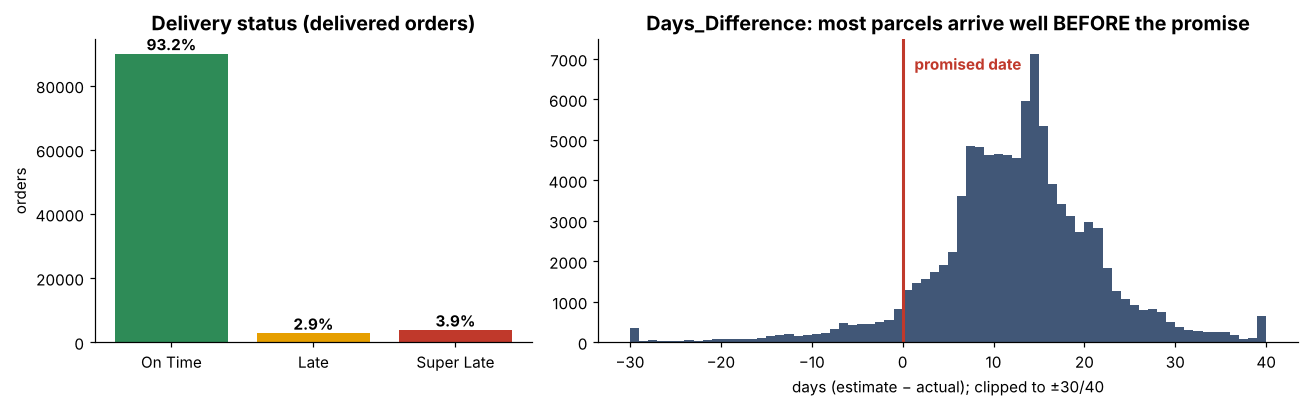

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios":[1,1.6]})
ax[0].bar(share.index, share.values, color=[STATUS_COLORS[i] for i in share.index])
for i, v in enumerate(share.values): ax[0].text(i, v, f"{v/len(d)*100:.1f}%", ha="center", va="bottom", fontweight="bold")
ax[0].set_title("Delivery status (delivered orders)"); ax[0].set_ylabel("orders")

ax[1].hist(d.Days_Difference.clip(-30, 40), bins=70, color=NAVY, alpha=.85)
ax[1].axvline(0, color=RED, lw=2); ax[1].text(0.5, ax[1].get_ylim()[1]*.9, "  promised date", color=RED, fontweight="bold")
ax[1].set_title("Days_Difference: most parcels arrive well BEFORE the promise"); ax[1].set_xlabel("days (estimate − actual); clipped to ±30/40")
plt.tight_layout(); plt.savefig(FIG/"01_status_distribution.png", bbox_inches="tight"); plt.show()

**Insight (and a correction to the CEO's gut feeling):** only ~7% of delivered orders miss their promised date, and the *typical* order arrives **~12 days early**. Veridi is not broadly "over-promising"; if anything its estimates are conservative on average. The problem must therefore be *concentrated*, which is what the next sections test.

## 3. The Geographic Heatmap (Story 3)
For each state: late rate (Late + Super Late), Super Late rate, volume and average review.  States with fewer than **100 delivered orders** are flagged `low_n`: their percentages swing wildly on a handful of parcels, so they are shown but not used for headline claims.

In [8]:
REGION = {**dict.fromkeys(["AC","AP","AM","PA","RO","RR","TO"], "North"),
          **dict.fromkeys(["AL","BA","CE","MA","PB","PE","PI","RN","SE"], "Northeast"),
          **dict.fromkeys(["DF","GO","MT","MS"], "Central-West"),
          **dict.fromkeys(["ES","MG","RJ","SP"], "Southeast"),
          **dict.fromkeys(["PR","RS","SC"], "South")}
REG_COLORS = {"North":"#7B5EA7","Northeast":RED,"Central-West":AMBER,"Southeast":NAVY,"South":GREEN}
d["region"] = d.customer_state.map(REGION)

d["promised_days"] = (d.order_estimated_delivery_date.dt.normalize() - d.order_purchase_timestamp.dt.normalize()).dt.days
d["actual_days"]   = (d.order_delivered_customer_date.dt.normalize() - d.order_purchase_timestamp.dt.normalize()).dt.days

state = (d.groupby("customer_state")
          .agg(orders=("order_id","count"),
               late_pct=("is_late","mean"),
               super_late_pct=("Delivery_Status", lambda s: (s=="Super Late").mean()),
               avg_review=("review_score","mean"),
               avg_days_diff=("Days_Difference","mean"),
               promised_days=("promised_days","mean"),
               actual_days=("actual_days","mean"))
          .assign(region=lambda x: x.index.map(REGION), low_n=lambda x: x.orders < 100)
          .sort_values("late_pct", ascending=False))
state_view = state.copy()
for c in ["late_pct","super_late_pct"]: state_view[c] = (state_view[c]*100).round(1)
state_view[["avg_review","avg_days_diff","promised_days","actual_days"]] = state_view[["avg_review","avg_days_diff","promised_days","actual_days"]].round(2)
state_view

,orders,late_pct,super_late_pct,avg_review,avg_days_diff,promised_days,actual_days,region,low_n
customer_state,,,,,,,,,
AL,397,21.4,12.8,3.85,8.71,33.21,24.50,Northeast,False
MA,717,17.4,10.3,3.83,9.57,31.08,21.51,Northeast,False
SE,335,15.2,11.6,3.91,10.02,31.48,21.46,Northeast,False
PI,476,13.9,7.4,3.99,11.31,30.70,19.39,Northeast,False
CE,1279,13.8,10.2,3.94,10.80,32.00,21.20,Northeast,False
RR,41,12.2,9.8,3.90,17.29,46.63,29.34,North,True
BA,3256,12.2,7.6,3.93,10.79,30.07,19.28,Northeast,False
RJ,12350,12.1,8.6,3.97,11.76,27.00,15.24,Southeast,False
PA,946,11.2,8.2,3.91,14.07,37.79,23.73,North,False


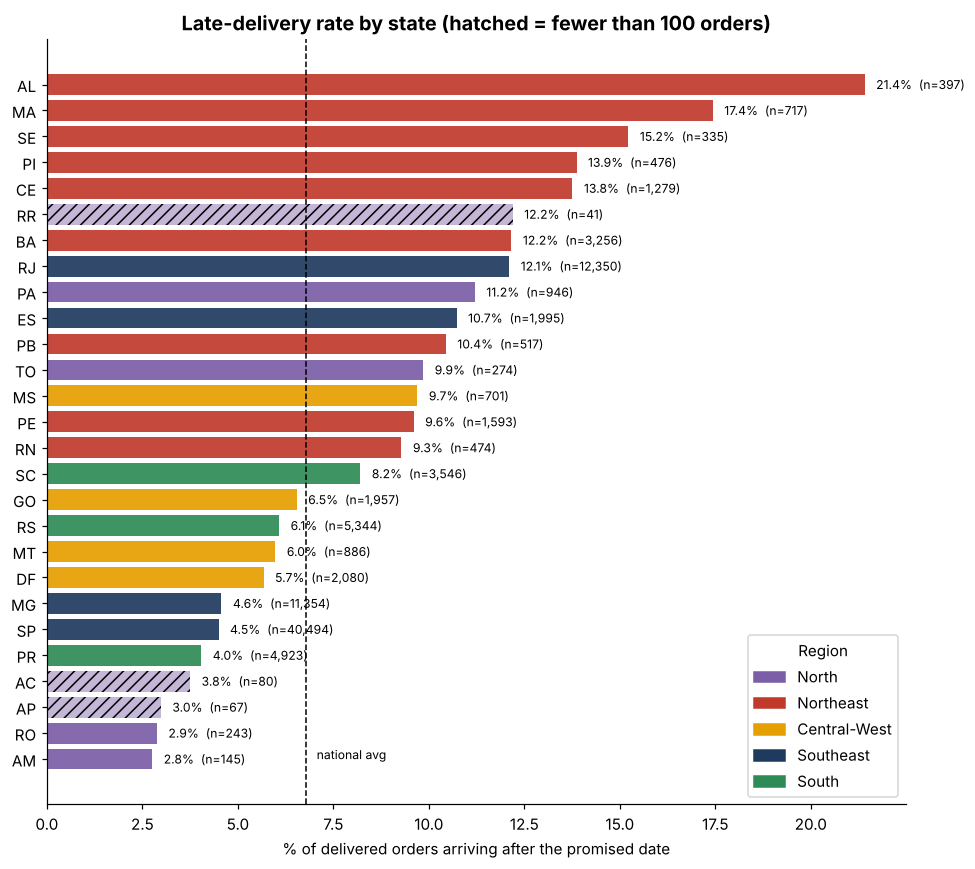

In [9]:
fig, ax = plt.subplots(figsize=(9, 8))
s = state.sort_values("late_pct")
colors = [REG_COLORS[r] for r in s.region]
bars = ax.barh(s.index, s.late_pct*100, color=colors, alpha=.92)
for b, low in zip(bars, s.low_n):
    if low: b.set_hatch("///"); b.set_alpha(.45)
for y, (v, n) in enumerate(zip(s.late_pct*100, s.orders)): ax.text(v+.3, y, f"{v:.1f}%  (n={n:,})", va="center", fontsize=8)
ax.axvline(d.is_late.mean()*100, color="black", ls="--", lw=1); ax.text(d.is_late.mean()*100+.2, 0, " national avg", fontsize=8)
ax.set_xlabel("% of delivered orders arriving after the promised date"); ax.set_title("Late-delivery rate by state (hatched = fewer than 100 orders)")
ax.legend(handles=[plt.Rectangle((0,0),1,1,color=c) for c in REG_COLORS.values()], labels=REG_COLORS.keys(), loc="lower right", title="Region")
plt.tight_layout(); plt.savefig(FIG/"02_late_rate_by_state.png", bbox_inches="tight"); plt.show()

### Tile-grid "map" of Brazil (each tile = one state, colour = late rate)

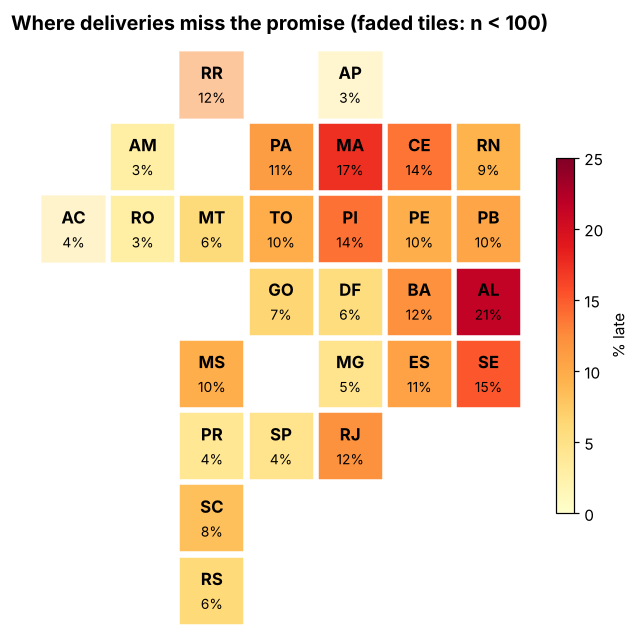

In [10]:
TILE = {"RR":(2,0),"AP":(4,0),"AM":(1,1),"PA":(3,1),"MA":(4,1),"CE":(5,1),"RN":(6,1),
        "AC":(0,2),"RO":(1,2),"MT":(2,2),"TO":(3,2),"PI":(4,2),"PE":(5,2),"PB":(6,2),
        "GO":(3,3),"DF":(4,3),"BA":(5,3),"AL":(6,3),"MS":(2,4),"MG":(4,4),"ES":(5,4),"SE":(6,4),
        "PR":(2,5),"SP":(3,5),"RJ":(4,5),"SC":(2,6),"RS":(2,7)}
fig, ax = plt.subplots(figsize=(7.2, 7))
cmap = plt.cm.YlOrRd; vmax = 0.25
for st, (x, y) in TILE.items():
    v = state.loc[st, "late_pct"]; low = state.loc[st, "low_n"]
    ax.add_patch(plt.Rectangle((x, -y), .94, .94, color=cmap(v/vmax), alpha=.5 if low else 1, ec="white"))
    ax.text(x+.47, -y+.55, st, ha="center", fontweight="bold", fontsize=11)
    ax.text(x+.47, -y+.22, f"{v*100:.0f}%", ha="center", fontsize=9)
ax.set_xlim(-.1, 7); ax.set_ylim(-7.1, 1.1); ax.axis("off")
sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(0, vmax*100)); cb = plt.colorbar(sm, ax=ax, shrink=.6); cb.set_label("% late")
ax.set_title("Where deliveries miss the promise (faded tiles: n < 100)")
plt.savefig(FIG/"03_tile_map.png", bbox_inches="tight"); plt.show()

### Is the problem regional or nationwide? Quantifying it
* **Concentration:** what share of all late orders comes from which region vs. its share of volume?
* **Remoteness test (brief's insight request):** no seller-location file was provided, so I use the great-circle distance from **São Paulo** (Brazil's commercial hub and the state with by far the most customers/sellers) to each state capital as a *proxy* for distance from the distribution centre.

In [11]:
reg = (d.groupby("region").agg(orders=("order_id","count"), late_orders=("is_late","sum"), late_pct=("is_late","mean"),
                               super_late_pct=("Delivery_Status", lambda s:(s=="Super Late").mean()), avg_review=("review_score","mean"))
         .assign(share_of_orders=lambda x: x.orders/x.orders.sum(), share_of_late=lambda x: x.late_orders/x.late_orders.sum())
         .sort_values("late_pct", ascending=False))
display(reg.assign(late_pct=lambda x:(x.late_pct*100).round(1), super_late_pct=lambda x:(x.super_late_pct*100).round(1),
                   share_of_orders=lambda x:(x.share_of_orders*100).round(1), share_of_late=lambda x:(x.share_of_late*100).round(1),
                   avg_review=lambda x:x.avg_review.round(2)))

CAP = {"AC":(-9.97,-67.81),"AL":(-9.67,-35.74),"AP":(0.03,-51.07),"AM":(-3.12,-60.02),"BA":(-12.97,-38.51),"CE":(-3.73,-38.52),
       "DF":(-15.79,-47.88),"ES":(-20.32,-40.34),"GO":(-16.68,-49.25),"MA":(-2.53,-44.30),"MT":(-15.60,-56.10),"MS":(-20.44,-54.65),
       "MG":(-19.92,-43.94),"PA":(-1.46,-48.50),"PB":(-7.12,-34.86),"PR":(-25.43,-49.27),"PE":(-8.05,-34.88),"PI":(-5.09,-42.80),
       "RJ":(-22.91,-43.17),"RN":(-5.79,-35.21),"RS":(-30.03,-51.23),"RO":(-8.76,-63.90),"RR":(2.82,-60.67),"SC":(-27.60,-48.55),
       "SP":(-23.55,-46.63),"SE":(-10.91,-37.07),"TO":(-10.18,-48.33)}
def km(a, b):
    la1, lo1, la2, lo2 = map(np.radians, (*a, *b))
    h = np.sin((la2-la1)/2)**2 + np.cos(la1)*np.cos(la2)*np.sin((lo2-lo1)/2)**2
    return 6371*2*np.arcsin(np.sqrt(h))
state["km_from_SP"] = [km(CAP["SP"], CAP[s]) for s in state.index]
ok = state[~state.low_n]
rho_late  = ok.km_from_SP.rank().corr(ok.late_pct.rank())          # Spearman
rho_promo = ok.km_from_SP.rank().corr(ok.promised_days.rank())
print(f"\nSpearman(distance from SP, late rate)      = {rho_late:+.2f}   (states with n>=100: {len(ok)})")
print(f"Spearman(distance from SP, promised days)  = {rho_promo:+.2f}")

,orders,late_orders,late_pct,super_late_pct,avg_review,share_of_orders,share_of_late
region,,,,,,,
Northeast,9044,1150.0,12.7,8.2,3.97,9.4,17.6
North,1796,154.0,8.6,5.8,4.03,1.9,2.4
Central-West,5624,367.0,6.5,3.5,4.13,5.8,5.6
Southeast,66193,4048.0,6.1,3.4,4.18,68.6,62.0
South,13813,815.0,5.9,3.3,4.19,14.3,12.5



Spearman(distance from SP, late rate)      = +0.25   (states with n>=100: 24)
Spearman(distance from SP, promised days)  = +0.89


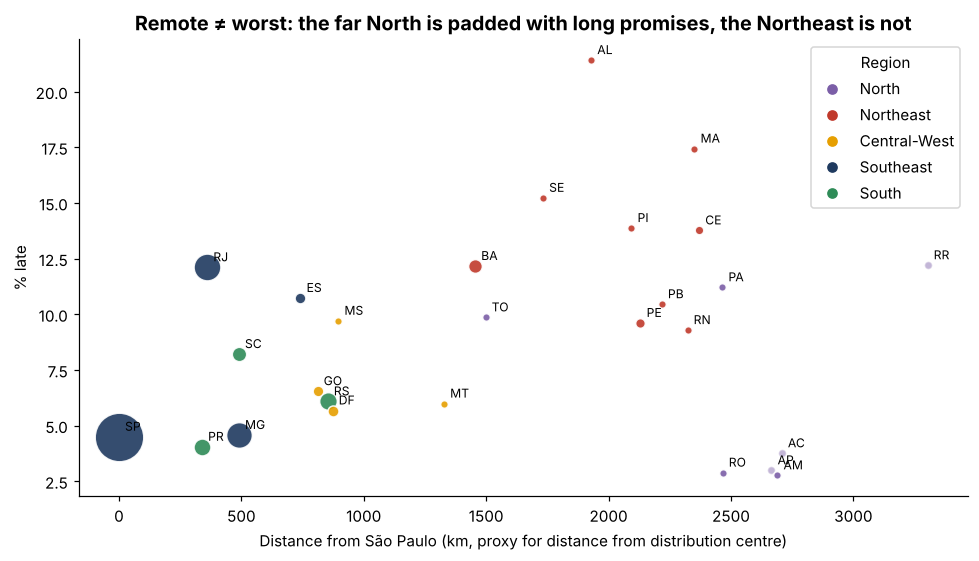

In [12]:
fig, ax = plt.subplots(figsize=(9, 5.2))
for st, r in state.iterrows():
    ax.scatter(r.km_from_SP, r.late_pct*100, s=max(r.orders/40, 25), color=REG_COLORS[r.region], alpha=.45 if r.low_n else .9, ec="white")
    ax.annotate(st, (r.km_from_SP, r.late_pct*100), xytext=(4,4), textcoords="offset points", fontsize=8)
ax.set_xlabel("Distance from São Paulo (km, proxy for distance from distribution centre)"); ax.set_ylabel("% late")
ax.set_title("Remote ≠ worst: the far North is padded with long promises, the Northeast is not")
ax.legend(handles=[plt.Line2D([],[],marker="o",ls="",color=c) for c in REG_COLORS.values()], labels=REG_COLORS.keys(), title="Region")
plt.tight_layout(); plt.savefig(FIG/"04_distance_vs_late.png", bbox_inches="tight"); plt.show()

**Insight:** distance alone does **not** explain lateness. The very remote Amazon states (AC, RO, AM, AP) are among the *best* performers, because Veridi already promises them roughly 40-45 days (promised lead time rises almost perfectly with distance, Spearman +0.89). The failing region is the **Northeast** (AL, MA, SE, CE, PI, BA), only moderately far from São Paulo, but promised delivery times that are too optimistic for how its logistics really perform. Rio de Janeiro also stands out: a core market, yet more than twice the late rate of São Paulo.

## 4. The Sentiment Correlation (Story 4)
Do late deliveries actually cause bad reviews? Compare review scores for On Time vs Late vs Super Late, and trace the score across the full delay range.

In [13]:
sent = (d.groupby("Delivery_Status").agg(orders=("order_id","count"), avg_review=("review_score","mean"),
                                         pct_1_2_star=("review_score", lambda s: (s<=2).sum()/s.notna().sum()),
                                         pct_5_star=("review_score", lambda s: (s==5).sum()/s.notna().sum()))
          .reindex(["On Time","Late","Super Late"]))
display(sent.round(3))
gap = sent.loc["On Time","avg_review"] - d[d.is_late==1].review_score.mean()
print(f"Average review: On Time {sent.loc['On Time','avg_review']:.2f}  vs  Late (any) {d[d.is_late==1].review_score.mean():.2f}  -> gap of {gap:.2f} stars")
print(f"Correlation (Days_Difference vs review_score): Pearson {d[['Days_Difference','review_score']].corr().iloc[0,1]:+.2f}")

,orders,avg_review,pct_1_2_star,pct_5_star
Delivery_Status,,,,
On Time,89936,4.290,0.093,0.623
Late,2770,2.988,0.411,0.283
Super Late,3764,1.737,0.782,0.078


Average review: On Time 4.29  vs  Late (any) 2.27  -> gap of 2.02 stars
Correlation (Days_Difference vs review_score): Pearson +0.27


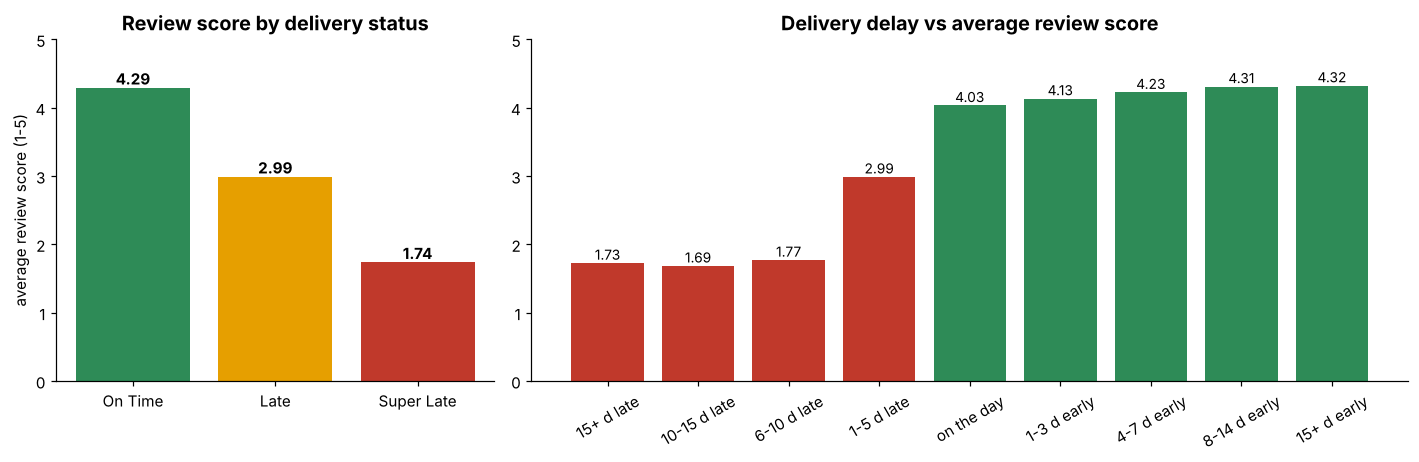

In [14]:
bins   = [-999,-15,-10,-5,-1,0,3,7,14,999]
labels = ["15+ d late","10-15 d late","6-10 d late","1-5 d late","on the day","1-3 d early","4-7 d early","8-14 d early","15+ d early"]
d["delay_bucket"] = pd.cut(d.Days_Difference, bins=[-999,-16,-11,-6,-1,0,3,7,14,999], labels=labels)
curve = d.groupby("delay_bucket").agg(orders=("order_id","count"), avg_review=("review_score","mean")).reset_index()

fig, ax = plt.subplots(1, 2, figsize=(13, 4.3), gridspec_kw={"width_ratios":[1,2]})
ax[0].bar(sent.index, sent.avg_review, color=[STATUS_COLORS[i] for i in sent.index])
for i, v in enumerate(sent.avg_review): ax[0].text(i, v+.05, f"{v:.2f}", ha="center", fontweight="bold")
ax[0].set_ylim(0, 5); ax[0].set_ylabel("average review score (1-5)"); ax[0].set_title("Review score by delivery status")

cols = [RED if "late" in l else GREEN for l in curve.delay_bucket.astype(str)]
ax[1].bar(curve.delay_bucket.astype(str), curve.avg_review, color=cols)
for i, v in enumerate(curve.avg_review): ax[1].text(i, v+.05, f"{v:.2f}", ha="center", fontsize=9)
ax[1].set_ylim(0, 5); ax[1].set_title("Delivery delay vs average review score"); ax[1].tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.savefig(FIG/"05_sentiment.png", bbox_inches="tight"); plt.show()

**Robustness check:** could low scores just reflect *unhappy regions* rather than lateness? If so, even **on-time** orders would score badly in the Northeast. They don't (below): the score tracks the delivery outcome, not the zip code.

In [15]:
chk = d.pivot_table(index="region", columns="Delivery_Status", values="review_score", aggfunc="mean")[["On Time","Late","Super Late"]].round(2)
display(chk)

Delivery_Status,On Time,Late,Super Late
region,,,
Central-West,4.26,2.78,1.65
North,4.20,3.23,1.62
Northeast,4.23,2.92,1.78
South,4.30,3.02,1.85
Southeast,4.30,3.01,1.71


**Insight:** this settles the CEO's causality question. Review score falls from **~4.3 (on time)** to **~3.0 (late)** to **~1.7 (super late)**. The cliff is steepest *after* the promise is broken, and an on-time parcel gets a ~4.2+ rating in **every** region. Logistics is the driver of the negative-review spike.

## 5. Bonus: The "Translation" Challenge
`product_category_name` is Portuguese. The brief points to `product_category_name_translation.csv`; this notebook **uses that file if it is in the folder, otherwise falls back to a built-in mapping** (all 73 categories present in `olist_products_dataset.csv`), so the notebook runs either way.

In [16]:
FALLBACK_EN = {"agro_industria_e_comercio":"agro_industry_and_commerce","alimentos":"food","alimentos_bebidas":"food_drink","artes":"art",
"artes_e_artesanato":"arts_and_craftmanship","artigos_de_festas":"party_supplies","artigos_de_natal":"christmas_supplies","audio":"audio",
"automotivo":"auto","bebes":"baby","bebidas":"drinks","beleza_saude":"health_beauty","brinquedos":"toys","cama_mesa_banho":"bed_bath_table",
"casa_conforto":"home_comfort","casa_conforto_2":"home_comfort_2","casa_construcao":"home_construction","cds_dvds_musicais":"cds_dvds_musicals",
"cine_foto":"cine_photo","climatizacao":"air_conditioning","consoles_games":"consoles_games","construcao_ferramentas_construcao":"construction_tools_construction",
"construcao_ferramentas_ferramentas":"costruction_tools_tools","construcao_ferramentas_iluminacao":"construction_tools_lights",
"construcao_ferramentas_jardim":"construction_tools_garden","construcao_ferramentas_seguranca":"construction_tools_safety","cool_stuff":"cool_stuff",
"dvds_blu_ray":"dvds_blu_ray","eletrodomesticos":"home_appliances","eletrodomesticos_2":"home_appliances_2","eletronicos":"electronics",
"eletroportateis":"small_appliances","esporte_lazer":"sports_leisure","fashion_bolsas_e_acessorios":"fashion_bags_accessories","fashion_calcados":"fashion_shoes",
"fashion_esporte":"fashion_sport","fashion_roupa_feminina":"fashio_female_clothing","fashion_roupa_infanto_juvenil":"fashion_childrens_clothes",
"fashion_roupa_masculina":"fashion_male_clothing","fashion_underwear_e_moda_praia":"fashion_underwear_beach","ferramentas_jardim":"garden_tools","flores":"flowers",
"fraldas_higiene":"diapers_and_hygiene","industria_comercio_e_negocios":"industry_commerce_and_business","informatica_acessorios":"computers_accessories",
"instrumentos_musicais":"musical_instruments","la_cuisine":"la_cuisine","livros_importados":"books_imported","livros_interesse_geral":"books_general_interest",
"livros_tecnicos":"books_technical","malas_acessorios":"luggage_accessories","market_place":"market_place","moveis_colchao_e_estofado":"furniture_mattress_and_upholstery",
"moveis_cozinha_area_de_servico_jantar_e_jardim":"kitchen_dining_laundry_garden_furniture","moveis_decoracao":"furniture_decor","moveis_escritorio":"office_furniture",
"moveis_quarto":"furniture_bedroom","moveis_sala":"furniture_living_room","musica":"music","papelaria":"stationery","pc_gamer":"pc_gamer","pcs":"computers",
"perfumaria":"perfumery","pet_shop":"pet_shop","portateis_casa_forno_e_cafe":"small_appliances_home_oven_and_coffee",
"portateis_cozinha_e_preparadores_de_alimentos":"portable_kitchen_food_preparers","relogios_presentes":"watches_gifts","seguros_e_servicos":"security_and_services",
"sinalizacao_e_seguranca":"signaling_and_security","tablets_impressao_imagem":"tablets_printing_image","telefonia":"telephony","telefonia_fixa":"fixed_telephony",
"utilidades_domesticas":"housewares"}

tr_path = DATA/"product_category_name_translation.csv"
if tr_path.exists():
    official = pd.read_csv(tr_path).set_index("product_category_name")["product_category_name_english"].to_dict()
    tr = {**FALLBACK_EN, **official}            # official file wins; fallback only fills categories the file lacks
    gaps = sorted(set(FALLBACK_EN) - set(official)); src = f"official translation CSV (+ fallback for {len(gaps)} categories it lacks: {gaps})"
else:
    tr = FALLBACK_EN; src = "built-in fallback mapping"
nice = lambda s: s.replace("_"," ").title()
products["category_en"] = products.product_category_name.map(tr).fillna("Unknown / uncategorised").map(lambda s: s if s.startswith("Unknown") else nice(s))
print(f"Translation source: {src}")
print(f"Products: {len(products):,} | translated: {products.category_en.ne('Unknown / uncategorised').sum():,} | untranslated (missing category): {products.category_en.eq('Unknown / uncategorised').sum():,}")
products.category_en.value_counts().head(8)

Translation source: official translation CSV (+ fallback for 2 categories it lacks: ['pc_gamer', 'portateis_cozinha_e_preparadores_de_alimentos'])
Products: 32,951 | translated: 32,341 | untranslated (missing category): 610


category_en
Bed Bath Table           3029
Sports Leisure           2867
Furniture Decor          2657
Health Beauty            2444
Housewares               2335
Auto                     1900
Computers Accessories    1639
Toys                     1411
Name: count, dtype: int64

### Category × delivery performance
Linking a **product** to an **order** requires the bridge table `olist_order_items_dataset.csv` (`order_id` ↔ `product_id`); the four files listed in the brief do not connect to each other without it. The cell below runs the full category analysis **if that file is in the folder** and otherwise says so explicitly instead of inventing a join.

An order can hold several products, so I assign each order its **primary category** (the category of its first item) to keep the one-row-per-order guarantee from Section 1.

Orders spanning more than one category: 0.8%  -> primary-category assignment is a safe simplification


,orders,late_pct,expected_late_pct,avg_review,avg_days,avg_weight_kg,excess_vs_geo
category_en,,,,,,,
Audio,344,11.9,7.2,3.85,13.46,1.25,4.7
Home Confort,370,9.5,6.6,3.91,13.48,3.11,2.9
Baby,2763,8.2,6.7,4.12,12.67,3.35,1.5
Office Furniture,1246,8.1,7.2,3.65,20.65,11.32,0.9
Electronics,2507,7.7,7.1,4.13,12.86,0.77,0.5
Furniture Living Room,409,7.6,7.4,4.09,13.92,7.91,0.1
Musical Instruments,607,7.6,7.0,4.25,13.06,3.20,0.6
Health Beauty,8608,7.5,6.8,4.23,12.04,1.07,0.7


... lowest late rates ...


,orders,late_pct,expected_late_pct,avg_review,avg_days,avg_weight_kg,excess_vs_geo
category_en,,,,,,,
Housewares,5688,5.4,6.4,4.20,11.05,3.35,-1.0
Pet Shop,1682,5.1,6.4,4.28,11.34,2.99,-1.3
Small Appliances,606,4.8,6.5,4.26,10.98,3.10,-1.7
Home Appliances,747,4.4,6.5,4.21,11.24,1.94,-2.1
Luggage Accessories,1008,4.3,6.6,4.38,10.84,5.81,-2.3


Spearman(category avg weight, late rate) = +0.09  over 32 categories with >= 300 orders


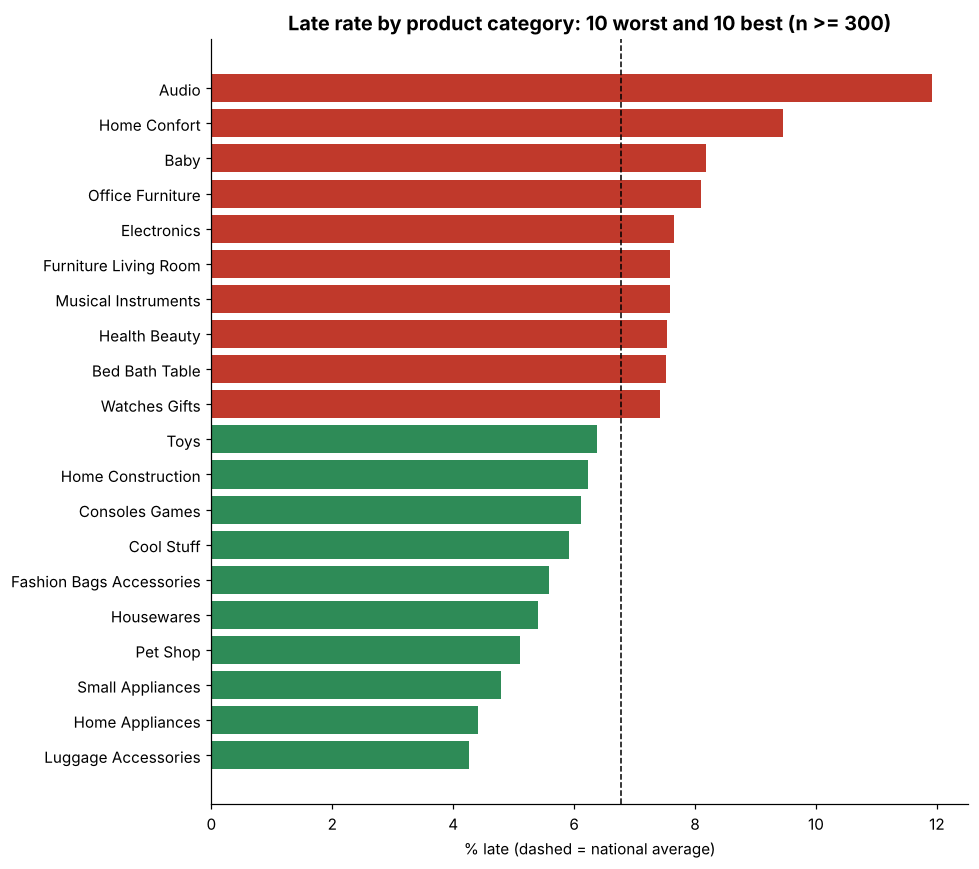

,orders,late_pct,expected_late_pct,super_late_pct,avg_review,avg_days,avg_weight_kg,excess_vs_geo,late_pct_SP_only
group,,,,,,,,,
Electronics,13898,6.9,7.0,3.8,4.08,13.01,0.77,-0.1,4.2
Everything else,74339,6.7,6.7,3.9,4.19,12.21,2.07,-0.0,4.5
Furniture,8233,7.3,6.8,4.2,4.01,14.23,4.62,0.5,5.1


In [17]:
items_path = DATA/"olist_order_items_dataset.csv"
cat_table, grp_table = None, None
if items_path.exists():
    items = pd.read_csv(items_path, usecols=["order_id","order_item_id","product_id"])
    first_item = items.sort_values(["order_id","order_item_id"]).drop_duplicates("order_id")
    multi = (items.merge(products[["product_id","category_en"]], on="product_id", how="left").groupby("order_id").category_en.nunique() > 1).mean()
    print(f"Orders spanning more than one category: {multi:.1%}  -> primary-category assignment is a safe simplification")
    oc = first_item.merge(products[["product_id","category_en","product_weight_g"]], on="product_id", how="left")[["order_id","category_en","product_weight_g"]]
    dc = d.merge(oc, on="order_id", how="left", validate="1:1")
    assert len(dc) == len(d)
    dc["category_en"] = dc.category_en.fillna("Unknown / uncategorised")
    # geography-adjusted view: what late rate would this category have if it shipped like the *average* order to the same states?
    dc["state_rate"] = dc.customer_state.map(state.late_pct)
    cat_table = (dc.groupby("category_en").agg(orders=("order_id","count"), late_pct=("is_late","mean"), expected_late_pct=("state_rate","mean"),
                    avg_review=("review_score","mean"), avg_days=("actual_days","mean"), avg_weight_kg=("product_weight_g", lambda x: x.mean()/1000))
                   .assign(excess_vs_geo=lambda x: x.late_pct - x.expected_late_pct).query("orders >= 300").sort_values("late_pct", ascending=False))
    show = cat_table.copy()
    for c_ in ["late_pct","expected_late_pct","excess_vs_geo"]: show[c_] = (show[c_]*100).round(1)
    display(show.round(2).head(8)); print("... lowest late rates ..."); display(show.round(2).tail(5))
    rho_w = cat_table.avg_weight_kg.rank().corr(cat_table.late_pct.rank())
    print(f"Spearman(category avg weight, late rate) = {rho_w:+.2f}  over {len(cat_table)} categories with >= 300 orders")

    fig, ax = plt.subplots(figsize=(9, 8)); t = pd.concat([cat_table.head(10), cat_table.tail(10)]).sort_values("late_pct")
    ax.barh(t.index, t.late_pct*100, color=[RED if v > d.is_late.mean() else GREEN for v in t.late_pct]); ax.axvline(d.is_late.mean()*100, color="black", ls="--", lw=1)
    ax.set_title("Late rate by product category: 10 worst and 10 best (n >= 300)"); ax.set_xlabel("% late (dashed = national average)")
    plt.tight_layout(); plt.savefig(FIG/"06_category_late.png", bbox_inches="tight"); plt.show()

    # The brief's explicit question: is "Furniture" harder to ship than "Electronics"?
    ELEC = {"Electronics","Computers Accessories","Computers","Pc Gamer","Telephony","Tablets Printing Image","Audio","Fixed Telephony"}
    dc["group"] = np.where(dc.category_en.str.contains("Furniture"), "Furniture", np.where(dc.category_en.isin(ELEC), "Electronics", "Everything else"))
    grp_table = (dc.groupby("group").agg(orders=("order_id","count"), late_pct=("is_late","mean"), expected_late_pct=("state_rate","mean"),
                    super_late_pct=("Delivery_Status", lambda s:(s=="Super Late").mean()), avg_review=("review_score","mean"),
                    avg_days=("actual_days","mean"), avg_weight_kg=("product_weight_g", lambda x: x.mean()/1000))
                   .assign(excess_vs_geo=lambda x: x.late_pct - x.expected_late_pct))
    grp_table["late_pct_SP_only"] = dc[dc.customer_state=="SP"].groupby("group").is_late.mean()
    g_show = grp_table.copy()
    for c_ in ["late_pct","expected_late_pct","super_late_pct","excess_vs_geo","late_pct_SP_only"]: g_show[c_] = (g_show[c_]*100).round(1)
    display(g_show.round(2))
else:
    print("olist_order_items_dataset.csv not found in this folder, so products cannot be linked to orders.")
    print("-> Category x delivery analysis SKIPPED. Drop that file next to the notebook and re-run this cell; no other change is needed.")

**Answer to the brief's question: is "Furniture" harder to ship than "Electronics"? Only slightly, and category is a second-order driver.**
* **Furniture 7.3% late vs Electronics 6.9%** (everything else 6.7%). Even after accounting for *where* each category ships (`excess_vs_geo`), furniture is only ~0.5 pt worse than expected, and electronics is on par. Within São Paulo alone the gap is 5.1% vs 4.2%.
* Furniture does take longer door to door (~14.2 vs ~13.0 days) and scores a little lower on reviews (4.01 vs 4.08), consistent with bulkier parcels.
* **Weight is not the driver:** category average weight and late rate are barely related (Spearman +0.09).
* **Outliers worth a look:** *Audio* (11.9% late, +4.7 pts vs geography-expected, but only 344 orders) and *Home Comfort* (9.5%). The most reliable categories are *Luggage Accessories*, *Home Appliances* and *Small Appliances* (4.3-4.8%).
* **Takeaway:** category spreads late rates from ~4% to ~12%, whereas **state** spreads them from ~3% to ~21%. Fixing the Northeast and Rio matters far more than any product-specific fix.

## 6. Candidate's Choice — **Recalibrated ETA** (promise vs. reality, by state)

**Why this matters to the business:** the audit shows the failure is not a delivery-speed problem everywhere, it is a **promise-setting problem in specific places**. A CEO can act on this directly: *"for state X, add N days to the estimate and we cut late deliveries to ~5%"*, and *"for state Y we over-pad by a week, so we can promise faster and win conversion."*

Method, per state:
1. `buffer_days` = promised − actual days (positive = padded).
2. `extra_days_for_95` = days to add to today's promise so that **95%** of historical orders would have arrived on time = `max(0, −5th percentile of Days_Difference)`.
3. **Where in the chain is the delay?** Split lead time into *seller handling* (purchase → carrier hand-off) and *carrier transit* (hand-off → customer) and compare late vs on-time orders.

In [18]:
recal = (d.groupby("customer_state")
           .agg(orders=("order_id","count"), promised_days=("promised_days","mean"), actual_days=("actual_days","mean"),
                late_pct=("is_late","mean"), p05_diff=("Days_Difference", lambda s: s.quantile(.05)))
           .assign(buffer_days=lambda x: x.promised_days - x.actual_days,
                   extra_days_for_95=lambda x: np.ceil((-x.p05_diff).clip(lower=0)).astype(int),
                   region=lambda x: x.index.map(REGION), low_n=lambda x: x.orders < 100)
           .sort_values("extra_days_for_95", ascending=False))
recal["new_promise_days"] = (recal.promised_days + recal.extra_days_for_95).round(1)
display(recal[["region","orders","promised_days","actual_days","buffer_days","late_pct","extra_days_for_95","new_promise_days"]].round(2).head(10))
print("\nStates where Veridi could PROMISE FASTER (largest cushion, already <=5% late):")
display(recal[(recal.late_pct<=.05)&(~recal.low_n)].sort_values("buffer_days", ascending=False)[["region","orders","promised_days","actual_days","buffer_days","late_pct"]].round(2).head(6))

,region,orders,promised_days,actual_days,buffer_days,late_pct,extra_days_for_95,new_promise_days
customer_state,,,,,,,,
AL,Northeast,397,33.21,24.50,8.71,0.21,13,46.2
MA,Northeast,717,31.08,21.51,9.57,0.17,13,44.1
CE,Northeast,1279,32.00,21.20,10.80,0.14,13,45.0
SE,Northeast,335,31.48,21.46,10.02,0.15,12,43.5
RJ,Southeast,12350,27.00,15.24,11.76,0.12,12,39.0
PA,North,946,37.79,23.73,14.07,0.11,10,47.8
RR,North,41,46.63,29.34,17.29,0.12,10,56.6
BA,Northeast,3256,30.07,19.28,10.79,0.12,9,39.1
PE,Northeast,1593,31.69,18.40,13.29,0.10,9,40.7



States where Veridi could PROMISE FASTER (largest cushion, already <=5% late):


,region,orders,promised_days,actual_days,buffer_days,late_pct
customer_state,,,,,,
RO,North,243,39.39,19.28,20.10,0.03
AM,North,145,45.92,26.36,19.57,0.03
PR,South,4923,25.25,11.94,13.31,0.04
MG,Southeast,11354,25.19,11.94,13.24,0.05
SP,Southeast,40494,19.78,8.70,11.08,0.04


,seller_handling_days,carrier_transit_days
is_late_lbl,,
Late,6.0,27.9
On Time,3.0,7.9


Northeast only (mean days):


,seller_handling_days,carrier_transit_days
is_late_lbl,,
Late,4.8,36.1
On Time,3.1,13.8


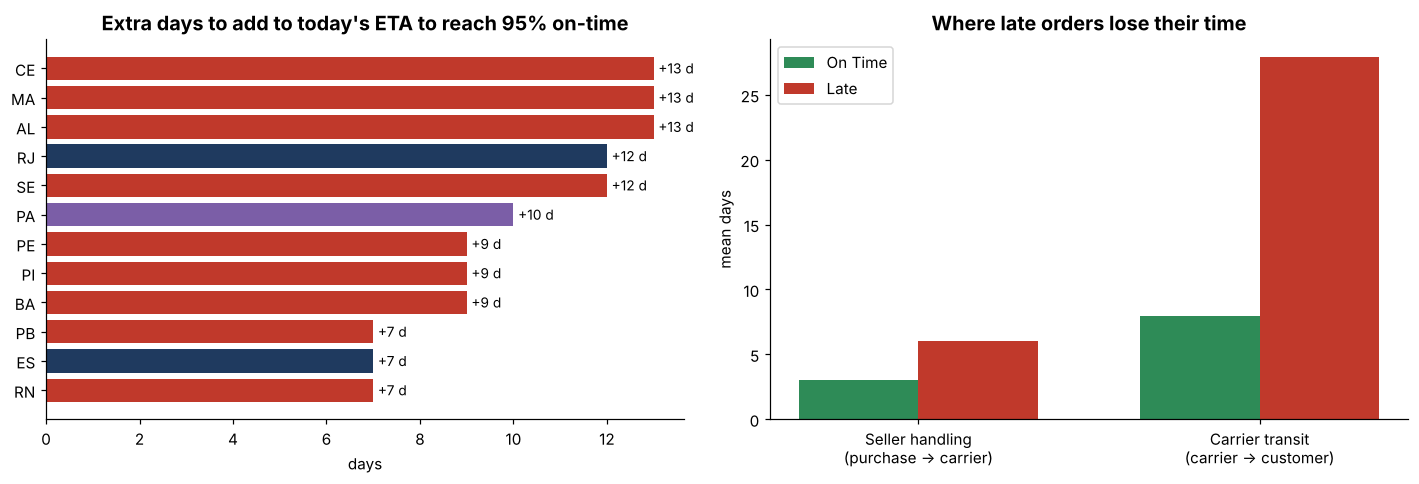

In [19]:
# Stage decomposition: which leg of the journey breaks when an order is late?
s = d.dropna(subset=["order_delivered_carrier_date"]).copy()
s["seller_handling_days"] = (s.order_delivered_carrier_date.dt.normalize() - s.order_purchase_timestamp.dt.normalize()).dt.days
s["carrier_transit_days"] = (s.order_delivered_customer_date.dt.normalize() - s.order_delivered_carrier_date.dt.normalize()).dt.days
s = s[(s.seller_handling_days >= 0) & (s.carrier_transit_days >= 0)]
s["is_late_lbl"] = np.where(s.is_late == 1, "Late", "On Time")
stage = s.groupby("is_late_lbl")[["seller_handling_days","carrier_transit_days"]].median()
stage_mean = s.groupby("is_late_lbl")[["seller_handling_days","carrier_transit_days"]].mean()
display(stage_mean.round(1))
nec = s[s.region == "Northeast"].groupby("is_late_lbl")[["seller_handling_days","carrier_transit_days"]].mean()
print("Northeast only (mean days):"); display(nec.round(1))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
r = recal[~recal.low_n].sort_values("extra_days_for_95").tail(12)
ax[0].barh(r.index, r.extra_days_for_95, color=[REG_COLORS[x] for x in r.region])
for y, v in enumerate(r.extra_days_for_95): ax[0].text(v+.1, y, f"+{v} d", va="center", fontsize=9)
ax[0].set_title("Extra days to add to today's ETA to reach 95% on-time"); ax[0].set_xlabel("days")
w = .35; x = np.arange(2)
ax[1].bar(x-w/2, stage_mean.loc["On Time"], w, label="On Time", color=GREEN); ax[1].bar(x+w/2, stage_mean.loc["Late"], w, label="Late", color=RED)
ax[1].set_xticks(x); ax[1].set_xticklabels(["Seller handling\n(purchase → carrier)","Carrier transit\n(carrier → customer)"])
ax[1].set_ylabel("mean days"); ax[1].set_title("Where late orders lose their time"); ax[1].legend()
plt.tight_layout(); plt.savefig(FIG/"07_recalibrated_eta.png", bbox_inches="tight"); plt.show()

**Reading it:** late orders are slow in **both** legs, but the carrier-transit leg is where the gap versus on-time orders is largest (about +20 days vs about +3 days for seller handling), so the fix is a carrier/ETA problem more than a seller-packing problem. Table above gives per-state ETA adjustments Veridi can load into its promise engine immediately.

## 7. Is the spike seasonal? (time view) and findings

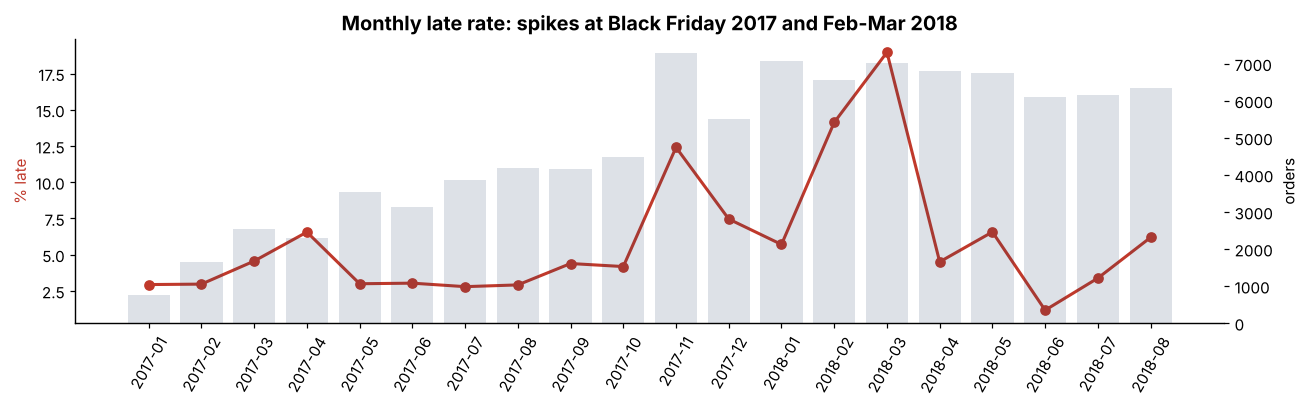

Worst months: 2018-03 (19.0%), 2018-02 (14.1%), 2017-11 (12.4%)
Late rate in worst months by region: {'Central-West': '16.2%', 'North': '22.0%', 'Northeast': '25.3%', 'South': '14.5%', 'Southeast': '13.7%'}


In [20]:
d["month"] = d.order_purchase_timestamp.dt.to_period("M").astype(str)
mon = d.groupby("month").agg(orders=("order_id","count"), late_pct=("is_late","mean"), avg_review=("review_score","mean")).query("orders >= 500")
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.plot(mon.index, mon.late_pct*100, marker="o", color=RED, lw=2); ax.set_ylabel("% late", color=RED)
ax2 = ax.twinx(); ax2.bar(mon.index, mon.orders, alpha=.15, color=NAVY); ax2.set_ylabel("orders")
ax.set_title("Monthly late rate: spikes at Black Friday 2017 and Feb-Mar 2018"); ax.tick_params(axis="x", rotation=60)
plt.tight_layout(); plt.savefig(FIG/"08_monthly.png", bbox_inches="tight"); plt.show()

peak = mon.late_pct.nlargest(3)
print("Worst months:", ", ".join(f"{m} ({pct(v)})" for m, v in peak.items()))
spike = d[d.month.isin(peak.index)]
print("Late rate in worst months by region:", spike.groupby("region").is_late.mean().map(pct).to_dict())

In [21]:
nat = d.is_late.mean(); ne = reg.loc["Northeast"]; se_sp = state.loc["SP"]
top = state[~state.low_n].head(3)
print("KEY FINDINGS (computed live)")
print(f"1. Nationwide, {pct(nat)} of delivered orders arrive late; typical order arrives {d.Days_Difference.median():.0f} days EARLY. It is NOT a broad over-promising problem.")
print(f"2. It IS regional: late rate ranges from {pct(state[~state.low_n].late_pct.min())} to {pct(state[~state.low_n].late_pct.max())} across states. Northeast = {pct(ne.late_pct)} late "
      f"({pct(ne.share_of_late)} of all late orders from {pct(ne.share_of_orders)} of volume) vs São Paulo {pct(se_sp.late_pct)}.")
print(f"3. Worst states (n>=100): " + ", ".join(f"{i} {pct(r.late_pct)}" for i, r in top.iterrows()))
print(f"4. Remote is not the same as worst: Spearman(distance, late rate) = {rho_late:+.2f}.")
print(f"5. Lateness drives sentiment: review {sent.loc['On Time','avg_review']:.2f} (on time) -> {sent.loc['Late','avg_review']:.2f} (late) -> {sent.loc['Super Late','avg_review']:.2f} (super late).")
absl = (state.orders*state.late_pct).sort_values(ascending=False); tot = absl.sum()
print("6. Biggest absolute contributors to late orders: " + ", ".join(f"{i} {pct(v/tot)}" for i, v in absl.head(3).items()) +
      f"  (RJ is {pct(state.loc['RJ','orders']/state.orders.sum())} of volume but {pct(absl['RJ']/tot)} of late orders).")
if grp_table is not None:
    print(f"7. Category is second-order: Furniture {pct(grp_table.loc['Furniture','late_pct'])} late vs Electronics {pct(grp_table.loc['Electronics','late_pct'])} (everything else {pct(grp_table.loc['Everything else','late_pct'])}); geography matters far more.")

KEY FINDINGS (computed live)
1. Nationwide, 6.8% of delivered orders arrive late; typical order arrives 12 days EARLY. It is NOT a broad over-promising problem.
2. It IS regional: late rate ranges from 2.8% to 21.4% across states. Northeast = 12.7% late (17.6% of all late orders from 9.4% of volume) vs São Paulo 4.5%.
3. Worst states (n>=100): AL 21.4%, MA 17.4%, SE 15.2%
4. Remote is not the same as worst: Spearman(distance, late rate) = +0.25.
5. Lateness drives sentiment: review 4.29 (on time) -> 2.99 (late) -> 1.74 (super late).
6. Biggest absolute contributors to late orders: SP 27.9%, RJ 22.9%, MG 7.9%  (RJ is 12.8% of volume but 22.9% of late orders).
7. Category is second-order: Furniture 7.3% late vs Electronics 6.9% (everything else 6.7%); geography matters far more.


In [22]:
# Export aggregate tables (used to feed the public dashboard); small files, safe to commit
out = {
 "overall": {"orders": int(len(d)), "late_pct": float(d.is_late.mean()), "super_late_pct": float((d.Delivery_Status=="Super Late").mean()),
             "median_days_early": float(d.Days_Difference.median()), "avg_review": float(d.review_score.mean())},
 "status": {k: {"orders": int(v.orders), "avg_review": float(v.avg_review), "pct_1_2": float(v.pct_1_2_star)} for k, v in sent.iterrows()},
 "state": [{"st": i, "region": r.region, "n": int(r.orders), "late": round(float(r.late_pct),4), "super": round(float(r.super_late_pct),4),
            "review": round(float(r.avg_review),3), "promised": round(float(r.promised_days),1), "actual": round(float(r.actual_days),1),
            "km": round(float(r.km_from_SP)), "extra95": int(recal.loc[i,"extra_days_for_95"])} for i, r in state.iterrows()],
 "region": [{"region": i, "n": int(r.orders), "late": round(float(r.late_pct),4), "share_orders": round(float(r.share_of_orders),4),
             "share_late": round(float(r.share_of_late),4), "review": round(float(r.avg_review),3)} for i, r in reg.iterrows()],
 "curve": [{"bucket": str(r.delay_bucket), "n": int(r.orders), "review": round(float(r.avg_review),3)} for _, r in curve.iterrows()],
 "monthly": [{"m": i, "n": int(r.orders), "late": round(float(r.late_pct),4)} for i, r in mon.iterrows()],
 "stage": {k: {c: round(float(v),2) for c, v in row.items()} for k, row in stage_mean.iterrows()},
 "rho_late": round(float(rho_late),3)}
if cat_table is not None:
    cc = pd.concat([cat_table.head(8), cat_table.tail(5)])
    out["category"] = [{"c": i, "n": int(r.orders), "late": round(float(r.late_pct),4), "exp": round(float(r.expected_late_pct),4), "review": round(float(r.avg_review),3)} for i, r in cc.iterrows()]
    out["groups"] = [{"g": i, "n": int(r.orders), "late": round(float(r.late_pct),4), "exp": round(float(r.expected_late_pct),4), "sp": round(float(r.late_pct_SP_only),4),
                      "review": round(float(r.avg_review),3), "days": round(float(r.avg_days),1), "kg": round(float(r.avg_weight_kg),2)} for i, r in grp_table.iterrows()]
    out["rho_weight"] = round(float(rho_w),3)
Path("dashboard_data.json").write_text(json.dumps(out))
print("dashboard_data.json written (", Path("dashboard_data.json").stat().st_size, "bytes )")

dashboard_data.json written ( 8332 bytes )
